In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs("EDAs", exist_ok=True)

RANDOM_STATE = 42
pd.set_option("display.max_columns", None)

df = pd.read_csv("H2_cleaned.csv", dtype={"Agent": str})
df["ReservationStatusDate"] = pd.to_datetime(df["ReservationStatusDate"])
print(df.shape)

(48991, 31)


In [2]:
MONTHS = ["January", "February", "March", "April", "May", "June", "July","August", "September", "October", "November", "December"]

def feature_vs_cancel(col):
    counts = pd.crosstab(df[col], df["IsCanceled"]).rename(columns={0: "not canceled", 1: "canceled"})
    pct = counts.div(counts.sum(axis=1), axis=0).mul(100).round(1)
    print(pd.concat({"bookings": counts, "%": pct}, axis=1))

    x = np.arange(len(pct))
    w = 0.38
    fig, ax = plt.subplots(figsize=(max(6, 0.9 * len(pct) + 2), 4))
    b1 = ax.bar(x - w / 2, pct["not canceled"], w, color="#2a78d6", label="not canceled")
    b2 = ax.bar(x + w / 2, pct["canceled"], w, color="#eb6834", label="canceled")
    for bars, name in [(b1, "not canceled"), (b2, "canceled")]:
        for b, v, n in zip(bars, pct[name], counts[name]):
            ax.text(b.get_x() + b.get_width() / 2, v + 1, f"{v:.0f}%\n{n:,}", ha="center", fontsize=7.5)
    ax.set_xticks(x, pct.index.astype(str), rotation=45 if len(pct) > 6 else 0)
    ax.set_ylim(0, 135)
    ax.set_yticks(range(0, 101, 20))
    ax.set_ylabel("% of bookings")
    ax.set_title(f"{col}: canceled vs not canceled", loc="left", fontweight="bold")
    ax.legend(frameon=False, ncol=2, loc="upper left")
    ax.spines[["top", "right"]].set_visible(False)
    plt.tight_layout()
    plt.savefig(f"EDAs/{col}.png", dpi=150)
    plt.show()

Leakage checks:

ReservationStatusDate

IsCanceled
0    100.0
1      7.2
dtype: float64


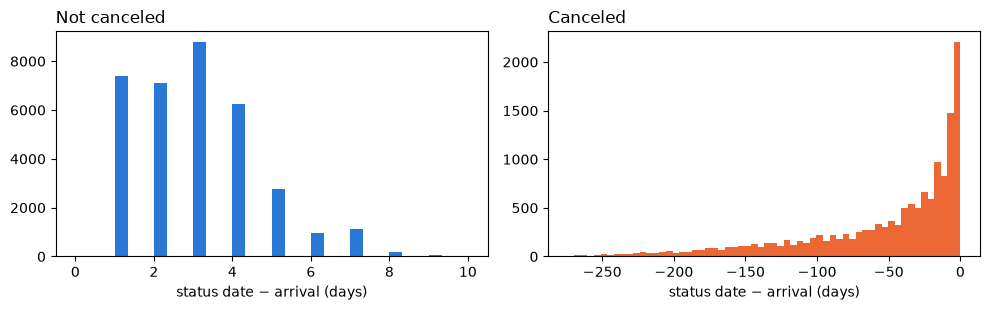

In [3]:
months = {m: i + 1 for i, m in enumerate(MONTHS)}
arrival = pd.to_datetime(dict(year=df["ArrivalDateYear"],month=df["ArrivalDateMonth"].map(months),day=df["ArrivalDateDayOfMonth"]))
days = (df["ReservationStatusDate"] - arrival).dt.days

print((days >= 0).groupby(df["IsCanceled"]).mean().mul(100).round(1))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].hist(days[df["IsCanceled"] == 0], bins=30, color="#2a78d6")
axes[0].set_title("Not canceled", loc="left")
axes[1].hist(days[df["IsCanceled"] == 1], bins=60, color="#eb6834")
axes[1].set_title("Canceled", loc="left")
for ax in axes:
    ax.set_xlabel("status date − arrival (days)")
plt.tight_layout()
plt.savefig("EDAs/status_date_minus_arrival.png", dpi=150)
plt.show()

status date is the checkout day always after arrival. Canceled is cancellation day always before arrival. Clear data leakage possible so we **Drop**

ReservationStatus

                      bookings                     %         
IsCanceled        not canceled canceled not canceled canceled
ReservationStatus                                            
Canceled                     0    13704          0.0    100.0
Check-Out                34642        0        100.0      0.0
No-Show                      0      645          0.0    100.0


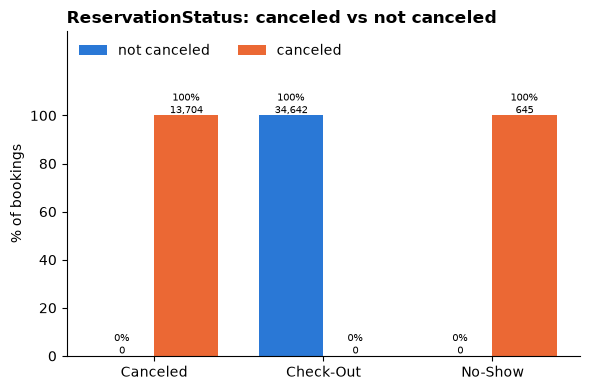

In [4]:
feature_vs_cancel("ReservationStatus")

checkout is 0% canceled, Canceled and No-Show are 100% **Drop**

In [5]:
df = df.drop(columns=["ReservationStatus", "ReservationStatusDate"])

RequiredCarParkingSpaces

                             bookings                     %         
IsCanceled               not canceled canceled not canceled canceled
RequiredCarParkingSpaces                                            
0                               32856    14349         69.6     30.4
1                                1783        0        100.0      0.0
2                                   1        0        100.0      0.0
3                                   2        0        100.0      0.0


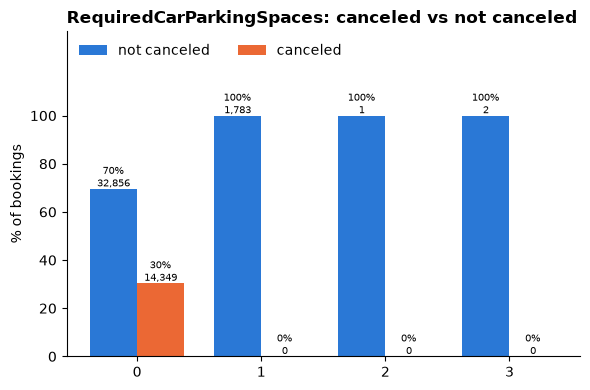

In [6]:
feature_vs_cancel("RequiredCarParkingSpaces")

No booking with parking space was canceled The value is most likely recorded when guest arrives so it is not known at booking time **Drop** 

In [7]:
df = df.drop(columns=["RequiredCarParkingSpaces"])

Features worth keeping

Correlation with IsCanceled

LeadTime                       0.198
TotalOfSpecialRequests        -0.173
BookingChanges                -0.119
ADR                            0.114
PreviousCancellations          0.107
Adults                         0.090
HasCompany                    -0.086
PreviousBookingsNotCanceled   -0.084
ArrivalDateYear                0.080
StaysInWeekNights              0.079
IsRepeatedGuest               -0.066
StaysInWeekendNights           0.037
Children                       0.032
DaysInWaitingList              0.026
Babies                        -0.021
ArrivalDateWeekNumber         -0.010
ArrivalDateDayOfMonth          0.005
Name: IsCanceled, dtype: float64


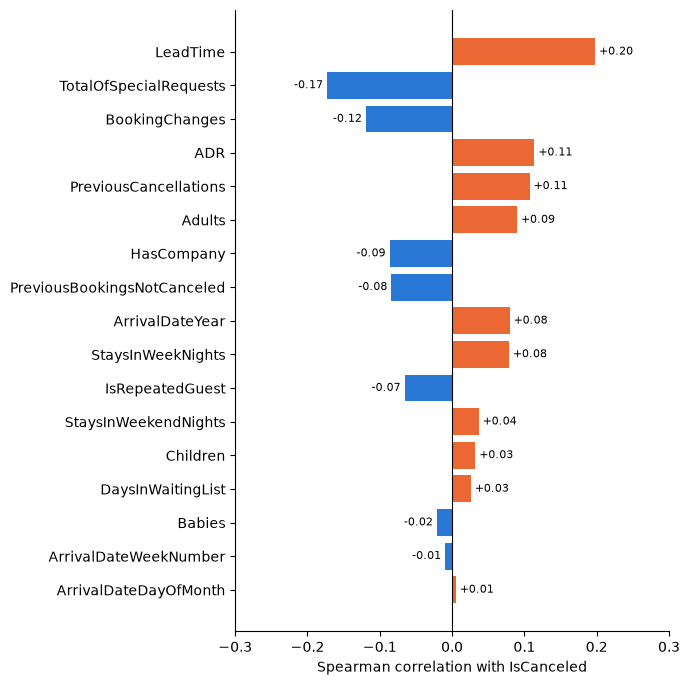

In [8]:
corr = df.select_dtypes("number").rank().corr()["IsCanceled"].drop("IsCanceled")
corr = corr.sort_values(key=abs, ascending=False)
print(corr.round(3))

plot = corr.iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 0.35 * len(plot) + 1))
ax.barh(plot.index, plot.values, color=["#eb6834" if v > 0 else "#2a78d6" for v in plot.values])
for i, v in enumerate(plot.values):
    ax.text(v, i, f" {v:+.2f} ", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlim(-0.3, 0.3)
ax.set_xlabel("Spearman correlation with IsCanceled")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("EDAs/correlation_with_iscanceled.png", dpi=150)
plt.show()

LeadTime has strongest positive coreletaion +0.20 where early bookings cancel more. Special requests is the strongest negative −0.17 where guests who make requests tend to come.

LeadTime

              count  mean   std  min   25%   50%    75%    max
IsCanceled                                                    
0           34642.0  63.1  64.7  0.0   9.0  40.0  100.0  274.0
1           14349.0  87.9  68.9  0.0  30.0  71.0  134.0  274.0
LeadTime
0-7        10.2
8-30       27.4
31-60      32.7
61-90      33.3
91-120     35.6
121-180    37.2
181-274    41.0
Name: IsCanceled, dtype: float64


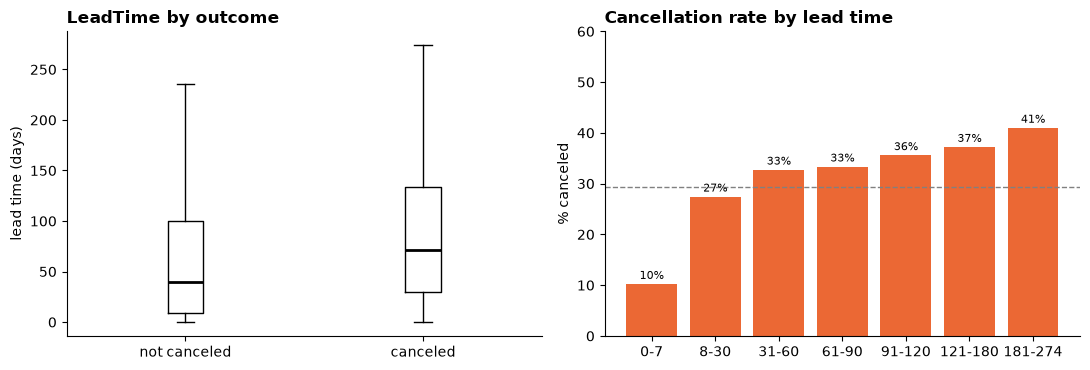

In [9]:
lt, target = df["LeadTime"], df["IsCanceled"]
print(df.groupby("IsCanceled")["LeadTime"].describe().round(1))

bands = pd.cut(lt, [-1, 7, 30, 60, 90, 120, 180, lt.max()],labels=["0-7", "8-30", "31-60", "61-90", "91-120", "121-180", f"181-{lt.max()}"])
rate = df.groupby(bands, observed=True)["IsCanceled"].mean() * 100
print(rate.round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].boxplot([lt[target == 0], lt[target == 1]], showfliers=False,medianprops=dict(color="black", lw=2))
axes[0].set_xticks([1, 2], ["not canceled", "canceled"])
axes[0].set_ylabel("lead time (days)")
axes[0].set_title("LeadTime by outcome", loc="left", fontweight="bold")

bars = axes[1].bar(rate.index.astype(str), rate.values, color="#eb6834")
axes[1].axhline(target.mean() * 100, color="gray", ls="--", lw=1)
for b, r in zip(bars, rate.values):
    axes[1].text(b.get_x() + b.get_width() / 2, r + 1, f"{r:.0f}%", ha="center", fontsize=8)
axes[1].set_ylim(0, 60)
axes[1].set_ylabel("% canceled")
axes[1].set_title("Cancellation rate by lead time", loc="left", fontweight="bold")
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("EDAs/leadtime.png", dpi=150)
plt.show()

Canceled bookings were made earlier median 71 vs 40 days and cancellation rises from 10 to 41% as lead time growsit is known at booking so no leakage. **Keep**

DepositType

                bookings                     %         
IsCanceled  not canceled canceled not canceled canceled
DepositType                                            
No Deposit         34613    13846         71.4     28.6
Non Refund            24      494          4.6     95.4
Refundable             5        9         35.7     64.3


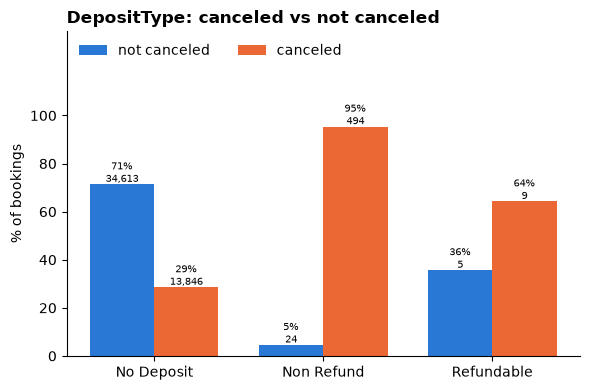

In [10]:
feature_vs_cancel("DepositType")

Non Refund bookings cancel 95% of the time and 28% for No Deposit Known at booking so **Keep**

Invalid rows

Undefined MarketSegment and DistributionChannel

                  bookings                     %         
IsCanceled    not canceled canceled not canceled canceled
MarketSegment                                            
Aviation               159       42         79.1     20.9
Complementary           56        5         91.8      8.2
Corporate             1917      253         88.3     11.7
Direct                4293      778         84.7     15.3
Groups                1401      555         71.6     28.4
Offline TA/TO         5498     1053         83.9     16.1
Online TA            21318    11662         64.6     35.4
Undefined                0        1          0.0    100.0


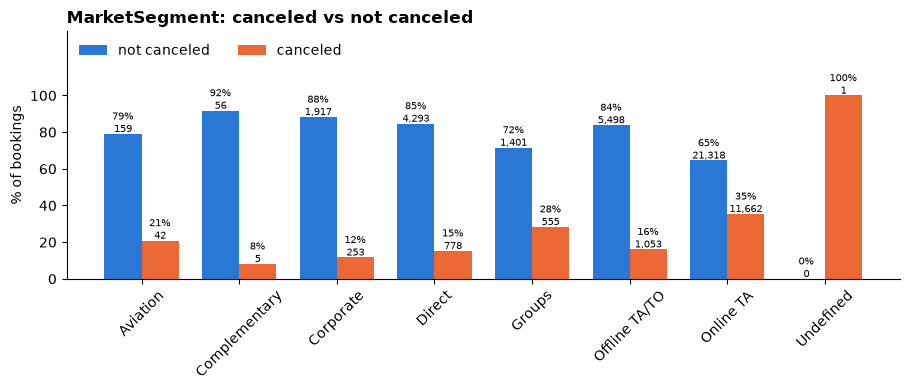

In [11]:
feature_vs_cancel("MarketSegment")

                        bookings                     %         
IsCanceled          not canceled canceled not canceled canceled
DistributionChannel                                            
Corporate                   2149      307         87.5     12.5
Direct                      4431      798         84.7     15.3
GDS                          130       33         79.8     20.2
TA/TO                      27932    13209         67.9     32.1
Undefined                      0        2          0.0    100.0


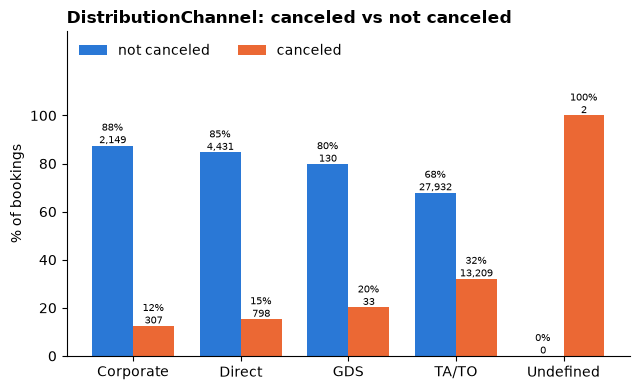

In [12]:
feature_vs_cancel("DistributionChannel")

Undefined is missing info **Drop the rows.**

In [13]:
before = len(df)
df = df[(df["MarketSegment"] != "Undefined") & (df["DistributionChannel"] != "Undefined")]
print("removed:", before - len(df))

removed: 2


Babies

               bookings                     %         
IsCanceled not canceled canceled not canceled canceled
Babies                                                
0                 34375    14290         70.6     29.4
1                   261       57         82.1     17.9
2                     6        0        100.0      0.0


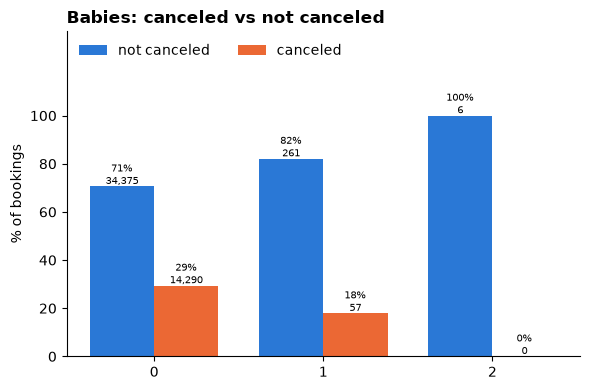

In [14]:
feature_vs_cancel("Babies")

In [15]:
before = len(df)
df = df[df["Babies"] <= 2]
print("removed:", before - len(df))

removed: 0


more drops

Agent

In [16]:
agents = df["Agent"].value_counts()
print("agent IDs:", len(agents))
print("IDs with < 50 bookings:", (agents < 50).sum())

agent IDs: 219
IDs with < 50 bookings: 172


hundreds of identified agent ids with very few bookings so **drop**

In [17]:
df = df.drop(columns=["Agent"], errors="ignore")
print(df.shape)

(48989, 27)


Train/test split

In [18]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["IsCanceled"])
y = df["IsCanceled"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("features:", list(X.columns))
print("train:", X_train.shape, "test:", X_test.shape)
print("cancel rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

features: ['LeadTime', 'ArrivalDateYear', 'ArrivalDateMonth', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'ReservedRoomType', 'AssignedRoomType', 'BookingChanges', 'DepositType', 'DaysInWaitingList', 'CustomerType', 'ADR', 'TotalOfSpecialRequests', 'HasCompany']
train: (39191, 26) test: (9798, 26)
cancel rate train/test: 0.293 0.293


Preprocessing pipeline

| Columns | Step |
|---|---|
| Categorical | One-hot  |
| LeadTime, stay durations | log(1 + x) + scaling |
| numerics | Scaling |

In [19]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop(columns=["IsCanceled"])
y = df["IsCanceled"]

cat_cols = X.select_dtypes(include=["object", "string"]).columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()
skewed_cols = ["LeadTime", "StaysInWeekendNights", "StaysInWeekNights"]

# categorical one-hot
X = pd.get_dummies(X, columns=cat_cols, dtype=int)

# numerical log for skewed columns
X[skewed_cols] = np.log1p(X[skewed_cols])

# split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

# numerical scaling
scaler = StandardScaler()
X_train_sc, X_test_sc = X_train.copy(), X_test.copy()
X_train_sc[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_sc[num_cols] = scaler.transform(X_test[num_cols])

print("categorical:", cat_cols)
print("numerical  :", num_cols)
print("train:", X_train_sc.shape, "test:", X_test_sc.shape)
print("cancel rate train/test:", round(y_train.mean(), 3), round(y_test.mean(), 3))

categorical: ['ArrivalDateMonth', 'Meal', 'Country', 'MarketSegment', 'DistributionChannel', 'ReservedRoomType', 'AssignedRoomType', 'DepositType', 'CustomerType']
numerical  : ['LeadTime', 'ArrivalDateYear', 'ArrivalDateWeekNumber', 'ArrivalDateDayOfMonth', 'StaysInWeekendNights', 'StaysInWeekNights', 'Adults', 'Children', 'Babies', 'IsRepeatedGuest', 'PreviousCancellations', 'PreviousBookingsNotCanceled', 'BookingChanges', 'DaysInWaitingList', 'ADR', 'TotalOfSpecialRequests', 'HasCompany']
train: (39191, 232) test: (9798, 232)
cancel rate train/test: 0.293 0.293


In [20]:
df.to_csv("H2_Cleaned_classification.csv", index=False)